# Kurtosis-adaptive constellation family – Figs. 2–4

This notebook reproduces Figs. 2–4 of

> [1] B. Geiger, L. Hampel, and L. Schmalen, "Joint power and adaptive-constellation optimization for OFDM-ISAC systems," in Proc. IEEE Conf. Integr. Sens. Commun. (ISAC), Lisbon, Portugal, Nov. 2026. [arXiv:2611.12166](https://arxiv.org/abs/2611.12166)

using the pretrained kurtosis-adaptive constellation family ($M = 64$). The constellation for a target kurtosis $\tilde\kappa \in [1, 2]$ is generated by three small neural networks in polar form, Eqs. (12)–(14) of [1]:

- radii: $r(\tilde\kappa) = \max\left(1 + \sqrt{\tilde\kappa - 1}\,\tanh(f_{\mathrm{NN,R}}(\tilde\kappa)),\ \epsilon_\mathrm{R}\right)$
- phases: $\theta(\tilde\kappa) = \tilde\theta + \pi \tanh(f_{\mathrm{NN},\theta}(\tilde\kappa))$, with $\tilde\theta_m = 2\pi(m-1)/M$
- probabilities: $\mathrm{Pr}(\cdot;\tilde\kappa) = \mathrm{Softmax}\left(\min((\tilde\kappa-1)/\epsilon_\mathrm{Pr}, 1)\, f_{\mathrm{NN,Pr}}(\tilde\kappa)\right)$

followed by a normalization to zero mean and unit average power. The implementation is in [`adaptive_constellation.py`](adaptive_constellation.py); it uses the same weight file as the MATLAB implementation (`../matlab/adaptive_constellation_weights.mat`).

Only the curves of the proposed adaptive constellation and the upper bound are reproduced; the reference curves of [1] (kurtosis-specific constellations, Cartesian parameterization, 64-PSK/64-QAM) are not included.

License: MIT (see `LICENSE` in the repository root).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from adaptive_constellation import (load_weights, generate_adaptive_constellation,
                                    mutual_information, mi_upper_bound_kurtosis)

weights = load_weights()
M = weights["M"]

kappa_target = np.round(np.arange(1, 2.001, 0.01), 2)   # target kurtosis values
x, p = generate_adaptive_constellation(kappa_target, weights)   # [K x M] each
kappa_achieved = np.sum(p * np.abs(x)**4, axis=1)        # kappa_n = E{|x_n|^4}

## Fig. 2: Adaptive constellation over the target kurtosis

The color indicates the target kurtosis $\tilde\kappa_n$, the marker size the probability of each constellation point. For $\tilde\kappa_n = 1$ the constellation is a uniformly distributed unit-modulus (PSK-like) constellation; with increasing target kurtosis, the points spread out radially and are probabilistically shaped towards a Gaussian-like distribution.

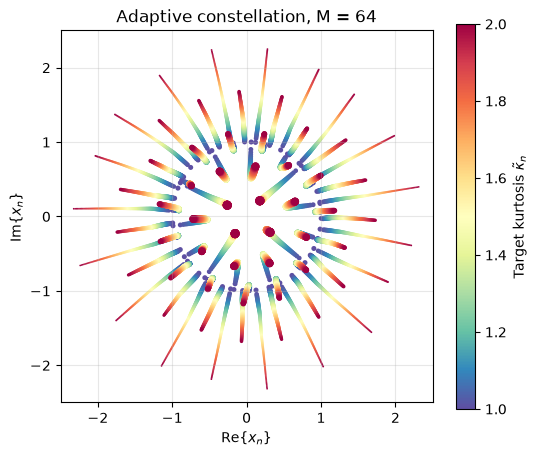

In [2]:
kappa_grid = np.repeat(kappa_target[:, None], M, axis=1)
marker_size = (0.5 + 25*np.sqrt(p))**2      # marker area ~ probability

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(x.real.ravel(), x.imag.ravel(), s=marker_size.ravel(),
                c=kappa_grid.ravel(), cmap="Spectral_r", vmin=1, vmax=2, linewidths=0)
ax.set_aspect("equal")
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
ax.grid(True, alpha=0.3)
ax.set_xlabel(r"$\mathrm{Re}\{x_n\}$"); ax.set_ylabel(r"$\mathrm{Im}\{x_n\}$")
ax.set_title(f"Adaptive constellation, M = {M}")
fig.colorbar(sc, ax=ax, label=r"Target kurtosis $\tilde{\kappa}_n$")
plt.show()

## Fig. 3: Achieved vs. target kurtosis

The achieved kurtosis $\kappa_n = \mathbb{E}\{|x_n|^4\}$ closely follows the target kurtosis $\tilde\kappa_n$. The inset zooms into the region close to unit-modulus constellations.

Max. deviation |kappa - kappa_target| = 1.07e-02


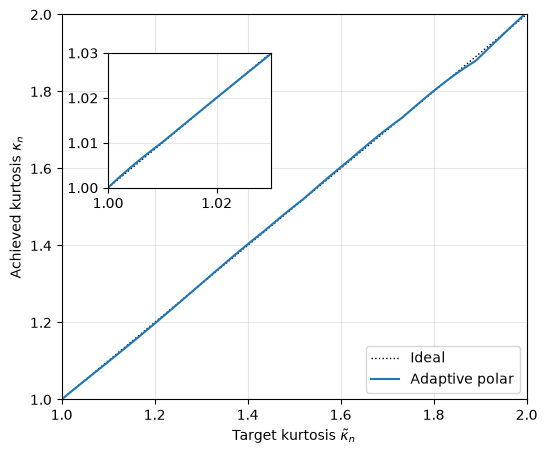

In [3]:
kappa_target_fine = np.arange(1, 1.0345, 0.001)          # fine grid for the inset
x_fine, p_fine = generate_adaptive_constellation(kappa_target_fine, weights)
kappa_achieved_fine = np.sum(p_fine * np.abs(x_fine)**4, axis=1)

print(f"Max. deviation |kappa - kappa_target| = "
      f"{np.max(np.abs(kappa_achieved - kappa_target)):.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(kappa_target, kappa_target, "k:", lw=1, label="Ideal")
ax.plot(kappa_target, kappa_achieved, lw=1.5, label="Adaptive polar")
ax.set_xlim(1, 2); ax.set_ylim(1, 2); ax.grid(True, alpha=0.3)
ax.set_xlabel(r"Target kurtosis $\tilde{\kappa}_n$")
ax.set_ylabel(r"Achieved kurtosis $\kappa_n$")
ax.legend(loc="lower right")

inset = ax.inset_axes([0.1, 0.55, 0.35, 0.35])          # zoom close to kappa = 1
inset.plot(kappa_target_fine, kappa_target_fine, "k:", lw=1)
inset.plot(kappa_target_fine, kappa_achieved_fine, lw=1.5)
inset.set_xlim(1, 1.03); inset.set_ylim(1, 1.03); inset.grid(True, alpha=0.3)
plt.show()

## Fig. 4: Mutual information vs. kurtosis

The MI of the adaptive constellation over an AWGN channel (computed with a Gauss-Hermite quadrature) is compared with the upper bound on the MI under a kurtosis constraint, Eq. (11) of [1], for SNRs of 10, 6, and 2 dB. The MI is plotted over the *achieved* kurtosis of the constellations. Computing all MI values takes less than a minute.

In [4]:
snr_dB = [10, 6, 2]                          # communication SNR 1/sigma_c^2

mi_adaptive = np.array([[mutual_information(x[k], p[k], snr)
                         for k in range(len(kappa_target))] for snr in snr_dB])
mi_upper_bound = np.array([mi_upper_bound_kurtosis(kappa_target, snr) for snr in snr_dB])

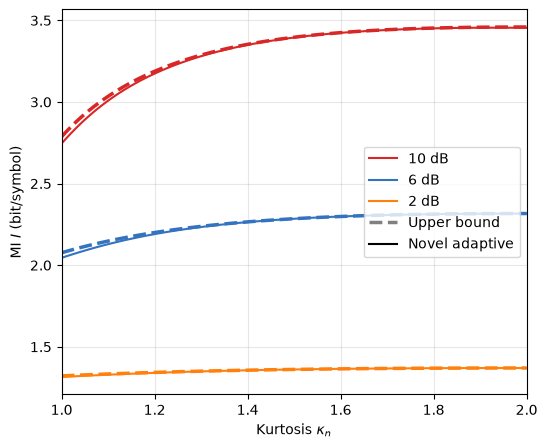

In [5]:
colors = [(0.85, 0.15, 0.15), (0.20, 0.45, 0.75), (1.00, 0.50, 0.05)]
fig, ax = plt.subplots(figsize=(6, 5))
for s, snr in enumerate(snr_dB):
    ax.plot(kappa_target, mi_upper_bound[s], "--", color=colors[s], lw=2.5)
    ax.plot(kappa_achieved, mi_adaptive[s], "-", color=colors[s], lw=1.5, label=f"{snr} dB")
ax.plot([], [], "--", color="0.5", lw=2.5, label="Upper bound")
ax.plot([], [], "-k", lw=1.5, label="Novel adaptive")
ax.set_xlim(1, 2); ax.grid(True, alpha=0.3)
ax.set_xlabel(r"Kurtosis $\kappa_n$"); ax.set_ylabel(r"MI $I$ (bit/symbol)")
ax.legend(loc="center right")
plt.show()